# Gross Code: Basic PPMs, Search Paths, and LER

In [1]:
from pathlib import Path
from dataclasses import asdict
import contextlib
import hashlib
import importlib.metadata as metadata
import io
import json
import logging
import os
import platform
import subprocess
import sys
import time

# Each decoder process uses one thread; parallelism is across shots.
for thread_variable in ("RAYON_NUM_THREADS", "OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[thread_variable] = "1"

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import stim
from IPython.display import display, Markdown
from IPython.utils.capture import capture_output
import lightstim
from lightstim.protocols.bb_ppm import BBPPMExperiment, BBPPMStep
from lightstim.qec_code.BB_code.ppm.shift import build_tour_de_gross_code, logical_shift_tableaus
from lightstim.qec_code.BB_code.ppm.lowering import BBPPMCompiler
from lightstim.qec_code.BB_code.ppm.native_reporting import export_basic_measurements
from lightstim.qec_code.BB_code.ppm.reporting import (
    format_logical_pauli, export_shift_and_native_catalogs,
    export_rotation_catalog, export_plan_report,
)
from lightstim.noise.config import NoiseConfig
from lightstim.simulation.decoder_backend import SimulationPipeline, DecoderConfig
from lightstim.plot.config import PlotConfig
from lightstim.plot.plotter import plot_custom
from lightstim.plot.utils import add_error_bars

assert Path(lightstim.__file__).resolve().is_relative_to(ROOT)
# The server runner can redirect generated files to a persistent results disk.
OUTPUT = Path(os.environ.get("BB_PPM_OUTPUT_DIR",
    ROOT / "notebooks" / "LogicalOps" / "assets" / "bb_ppm")).expanduser().resolve()
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)

def display_path(path, *, base=OUTPUT):
    """Format printed paths relative to their stated base directory."""
    return Path(os.path.relpath(Path(path).resolve(), Path(base).resolve())).as_posix()


ROUNDS = 10  # syndrome-extraction rounds per basic LPU measurement
P_VALUES = (1e-4, 5e-4, 1e-3)
SHOTS_BY_P = {1e-4: 100_000, 5e-4: 10_000, 1e-3: 10_000}
WORKER_PROCESSES = 192
THREADS_PER_WORKER = 1
NOISE_MODEL = "circuit_level_with_idling"
DECODER_NAME = "relay-bp"
# Frozen after training; validated on independent full-circuit samples.
DECODER_PARAMS = {
    "alpha": 0.8, "gamma0": 0.5,
    "pre_iter": 320, "num_sets": 600, "set_max_iter": 60,
    "gamma_dist_interval": (-0.1, 0.5), "stop_nconv": 5,
    "stopping_criterion": "nconv", "logging": False, "seed": 0,
}
LARGE_SAMPLE_RUN = Path(os.environ.get("BB_PPM_LARGE_SAMPLE_RUN",
    ROOT.parent / "bb_ppm_results" / "full_circuit_tuning" / "large_sample_runs" /
    "20261117_frozen_192")).expanduser().resolve()
MIDPOINT_SAMPLE_RUN = Path(os.environ.get("BB_PPM_MIDPOINT_SAMPLE_RUN",
    ROOT.parent / "bb_ppm_results" / "full_circuit_tuning" / "large_sample_runs" /
    "20261118_p0005_192")).expanduser().resolve()
RESUME_IF_STOPPED = True  # attach to the active run; resume saved work only if stopped

versions = {name: metadata.version(name) for name in
            ("stim", "numpy", "pandas", "relay-bp", "nbformat", "matplotlib")}
git_base = ["git", "--git-dir", str(ROOT / ".git"), "--work-tree", str(ROOT)]
git_env = dict(os.environ, GIT_OPTIONAL_LOCKS="0")
revision_result = subprocess.run(git_base + ["rev-parse", "HEAD"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
status_result = subprocess.run(git_base + ["status", "--porcelain"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
revision = revision_result.stdout.strip() if revision_result.returncode == 0 else None
git_dirty = bool(status_result.stdout.strip()) if status_result.returncode == 0 else None
runtime = {"commit": revision, "git_dirty": git_dirty,
           "python": platform.python_version(),
           "rayon_num_threads": os.environ.get("RAYON_NUM_THREADS", "automatic"), **versions}
print("LightStim:", display_path(lightstim.__file__, base=ROOT))
print("Output folder:", display_path(OUTPUT, base=ROOT))
print("Paths above are relative to the repository; artifact paths below are relative to Output folder.")
display(pd.Series(runtime, name="runtime"))


LightStim: lightstim/__init__.py
Output folder: notebooks/LogicalOps/assets/bb_ppm
Paths above are relative to the repository; artifact paths below are relative to Output folder.
commit               55732e09466071bdea776d48941ea0399d4b2e85
git_dirty                                                True
python                                                3.12.15
rayon_num_threads                                           1
stim                                                   1.16.0
numpy                                                   2.2.6
pandas                                                  3.1.1
relay-bp                                                0.2.2
nbformat                                               5.11.1
matplotlib                                             3.11.2
Name: runtime, dtype: object


## Cell 1 · 15 Basic LPU Measurements and Stabilizer Definitions

In [2]:
basic_rows = export_basic_measurements(OUTPUT / "stabilizer_definition", validate=True)
assert len(basic_rows) == 15
display(pd.DataFrame(basic_rows)[[
    "target", "lpu_mode", "vertex_checks", "cycle_checks", "edge_qubits",
    "modified_bb_checks", "validation_status",
]])
print("All 15 stabilizer definitions:", display_path(OUTPUT / "stabilizer_definition"))
print("All 15 measurement summaries:", display_path(OUTPUT / "stabilizer_definition" / "manifest.json"))


,target,lpu_mode,vertex_checks,cycle_checks,edge_qubits,modified_bb_checks,validation_status
0,X7,right,12,3,18,18,passed
1,Y7,full,23,19,47,36,passed
2,Z7,left,12,5,18,18,passed
3,X1,left,12,5,18,18,passed
4,X1 X7,full,23,19,47,36,passed
5,X1 Y7,full,23,19,47,54,passed
6,X1 Z7,left,12,5,18,36,passed
7,Y1,full,23,19,47,36,passed
8,Y1 X7,full,23,19,47,54,passed
9,Y1 Y7,full,23,19,47,72,passed


All 15 stabilizer definitions: stabilizer_definition
All 15 measurement summaries: stabilizer_definition/manifest.json


## Cell 2 · 36 Logical Shifts and 540 Native Measurements

In [3]:
from IPython.display import HTML

gross = build_tour_de_gross_code()
compiler = BBPPMCompiler(logical_shift_tableaus(gross))
catalogs = export_shift_and_native_catalogs(compiler, gross, OUTPUT)
shift_rows = catalogs["rows"]["shifts"]
native_rows = catalogs["rows"]["native_measurements"]
assert len(shift_rows) == 36 and len(native_rows) == 540
display(pd.DataFrame(shift_rows)[[
    "shift", "inverse_shift",
]])
native_table = pd.DataFrame(native_rows)
# Preview genuinely shifted entries; catalogue ordering is by Pauli string.
shifted_preview = native_table[(native_table["shift_x"] != 0) | (native_table["shift_y"] != 0)].head(10)
display(Markdown(f"Showing {len(shifted_preview)} examples out of {len(native_rows)} native measurements."))
display(HTML(shifted_preview[[
    "basic_measurement", "shift", "conjugated_pauli", "chronology",
]].rename(columns={
    "basic_measurement": "before shift",
    "conjugated_pauli": "after shift",
}).to_html(index=False)))
print("Distinct shifts:", len(shift_rows))
print("Native measurements:", len(native_rows))
for name, path in catalogs["paths"].items():
    print(f"{name}: {display_path(path)}")


,shift,inverse_shift
0,"x: 0, y: 0","x: 0, y: 0"
1,"x: 0, y: 1","x: 0, y: 5"
2,"x: 0, y: 2","x: 0, y: 4"
3,"x: 0, y: 3","x: 0, y: 3"
4,"x: 0, y: 4","x: 0, y: 2"
5,"x: 0, y: 5","x: 0, y: 1"
6,"x: 1, y: 0","x: 5, y: 0"
7,"x: 1, y: 1","x: 5, y: 5"
8,"x: 1, y: 2","x: 5, y: 4"
9,"x: 1, y: 3","x: 5, y: 3"


Showing 10 examples out of 540 native measurements.

before shift,shift,after shift,chronology
+X7,"x: 3, y: 5",+X12,"x: 3, y: 1 -> Measure(+X7) -> x: 3, y: 5"
+Z7,"x: 2, y: 4",+Z12,"x: 4, y: 2 -> Measure(+Z7) -> x: 2, y: 4"
+X7,"x: 5, y: 5",+X11,"x: 1, y: 1 -> Measure(+X7) -> x: 5, y: 5"
+X7,"x: 1, y: 5",+X11 X12,"x: 5, y: 1 -> Measure(+X7) -> x: 1, y: 5"
+Z7,"x: 1, y: 2",+Z11,"x: 5, y: 4 -> Measure(+Z7) -> x: 1, y: 2"
+X7,"x: 4, y: 1",+X10,"x: 2, y: 5 -> Measure(+X7) -> x: 4, y: 1"
+X7,"x: 4, y: 0",+X10 X11 X12,"x: 2, y: 0 -> Measure(+X7) -> x: 4, y: 0"
+Z7,"x: 2, y: 5",+Z10,"x: 4, y: 1 -> Measure(+Z7) -> x: 2, y: 5"
+Z7,"x: 5, y: 0",+Z10 Z12,"x: 1, y: 0 -> Measure(+Z7) -> x: 5, y: 0"
+Z7,"x: 0, y: 2",+Z10 Z11,"x: 0, y: 4 -> Measure(+Z7) -> x: 0, y: 2"


Distinct shifts: 36
Native measurements: 540
shifts_json: shifts/shifts.json
shifts_csv: shifts/shifts.csv
native_json: native_measurements/native_measurements.json
native_csv: native_measurements/native_measurements.csv


## Cell 3 · 245 Implementable Nontrivial Rotation Axes $A$

In [4]:
rotation_catalog = export_rotation_catalog(compiler, OUTPUT)
axis_rows = rotation_catalog["rows"]["axes"]
implementation_rows = rotation_catalog["rows"]["implementations"]
assert len(axis_rows) == 245 and len(implementation_rows) == 253
axis_preview = pd.DataFrame(axis_rows).head(10)
display(Markdown(f"Showing {len(axis_preview)} examples out of {len(axis_rows)} distinct available rotation axes A."))
display(HTML(axis_preview[[
    "axis", "implementation_count", "chosen_joint",
    "chosen_shift", "chosen_basic", "prepare", "readout", "forward_correction",
]].rename(columns={
    "axis": "axis (A)", "chosen_joint": "chosen_joint (Q₁A)",
}).to_html(index=False)))
print("Nontrivial Q1 A implementations:", len(implementation_rows))
print("Distinct nontrivial data rotation axes A:", len(axis_rows))
for name, path in rotation_catalog["paths"].items():
    print(f"{name}: {display_path(path)}")


Showing 10 examples out of 245 distinct available rotation axes A.

axis (A),implementation_count,chosen_joint (Q₁A),chosen_shift,chosen_basic,prepare,readout,forward_correction
+X7,3,+X1 X7,"x: 0, y: 0",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+Y7,3,+X1 Y7,"x: 0, y: 0",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A
+Z7,3,+X1 Z7,"x: 0, y: 0",+X1 Z7,Z1,Y1,r*m*s = +1: apply/track A
+Z6,1,+Z1 Z6,"x: 0, y: 5",+Z1,Y1,X1,r*m*s = +1: apply/track A
+Z6 X8 X11,1,+Z1 Z6 X8 X11,"x: 0, y: 5",+Z1 X7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Y8 X11,1,+Z1 Z6 Z7 Y8 X11,"x: 0, y: 5",+Z1 Y7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Z8,1,+Z1 Z6 Z7 Z8,"x: 0, y: 5",+Z1 Z7,Y1,X1,r*m*s = +1: apply/track A
+X4 X6,1,+X1 X4 X6,"x: 5, y: 3",+X1,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 X7 X8 X10,1,+X1 X4 X6 X7 X8 X10,"x: 5, y: 3",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 Y7 X8 Z9 X10 Z11,1,+X1 X4 X6 Y7 X8 Z9 X10 Z11,"x: 5, y: 3",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A


Nontrivial Q1 A implementations: 253
Distinct nontrivial data rotation axes A: 245
axes_json: rotation_axes/rotation_axes.json
axes_csv: rotation_axes/rotation_axes.csv
implementations_json: rotation_axes/rotation_implementations.json
implementations_csv: rotation_axes/rotation_implementations.csv


## Cell 4 · Bidirectional Search, Selected Path, and Full Operation Sequence

Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New, total, and frontier counts refer to distinct Pauli operators.

**PPM 0 — target: +X2 Z7 X12**

Search round,Expanded side,Target new,Target total,Target frontier,Native new,Native total,Native frontier,Connected,Meeting point
0,Initialization,1,1,1,245,245,245,No,—
1,target,100,101,100,0,245,245,Yes,+Y7


,step,rotation,before,axis,direction,after
0,0,0,+X2 Z7 X12,+X2 X7 X12,1,+Y7


The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage.

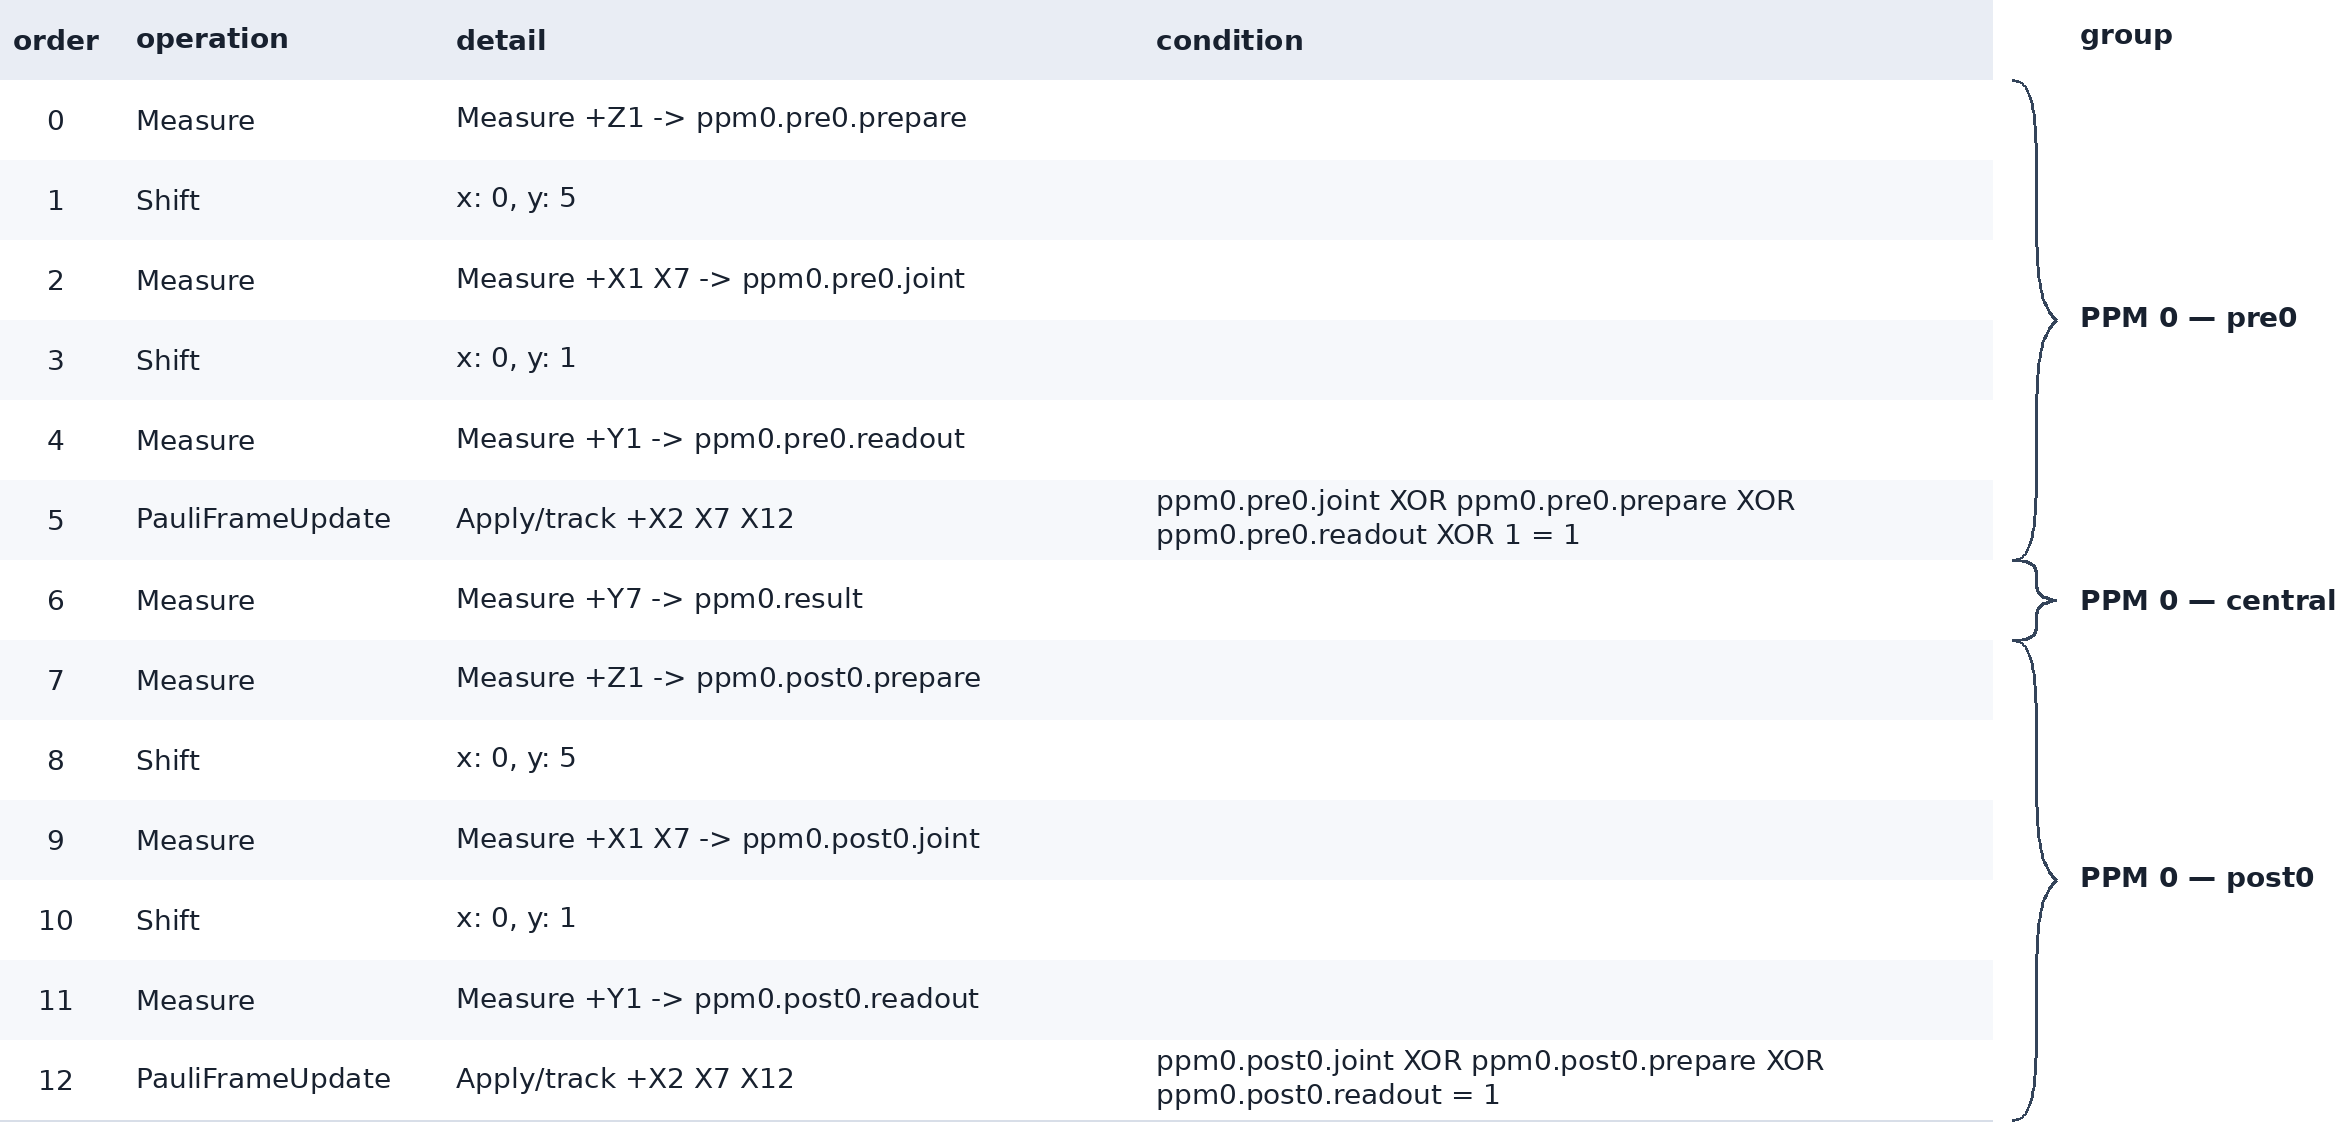

,step,measurements,shifts,frame_updates,output
0,0,7,4,2,ppm0.result


Compiled-plan SHA256: f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37
plans_json: searches/plans.json
summary_csv: searches/plan_summary.csv
search_csv: searches/search_progress.csv
path_csv: searches/selected_paths.csv
operations_csv: searches/operations.csv


In [5]:
ppm_sequence = [BBPPMStep(((2, "X"), (7, "Z"), (12, "X")))]
# Advanced input example:
# ppm_sequence = [BBPPMStep(((2, "X"), (8, "X"), (9, "X")))]

plans = tuple(compiler.compile(step.targets, prefix=f"ppm{i}")
              for i, step in enumerate(ppm_sequence))
plan_report = export_plan_report(compiler, plans, OUTPUT)
from IPython.display import HTML

display(Markdown("Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New, total, and frontier counts refer to distinct Pauli operators."))
for step, plan in enumerate(plans):
    display(Markdown(f"**PPM {step} — target: {format_logical_pauli(plan.target)}**"))
    if plan.search_status == "cached":
        display(Markdown("This target reuses a cached path. The records below are from its original search; no new expansion was performed."))
    search_rows = [row for row in plan_report["rows"]["search"] if row["step"] == step]
    if search_rows:
        search_table = pd.DataFrame(search_rows)[[
            "round", "expanded_side", "target_new", "target_total", "target_frontier",
            "native_new", "native_total", "native_frontier", "connected", "meeting_pauli",
        ]].copy()
        search_table["expanded_side"] = search_table["expanded_side"].map({
            "initial": "Initialization", "target": "target", "native": "native"})
        search_table["connected"] = search_table["connected"].map({True: "Yes", False: "No"})
        search_table["meeting_pauli"] = search_table["meeting_pauli"].fillna("—")
        search_table = search_table.rename(columns={
            "round": "Search round", "expanded_side": "Expanded side",
            "target_new": "Target new", "target_total": "Target total",
            "target_frontier": "Target frontier", "native_new": "Native new",
            "native_total": "Native total", "native_frontier": "Native frontier",
            "connected": "Connected", "meeting_pauli": "Meeting point",
        })
        display(HTML(search_table.to_html(index=False)))
    else:
        display(Markdown("This target requires no bidirectional search; the measurement plan is generated directly."))
path_table = pd.DataFrame(plan_report["rows"]["path"])
if len(path_table):
    display(path_table[["step", "rotation", "before", "axis", "direction", "after"]])
else:
    print("This target needs no Clifford search path.")

from base64 import b64encode
from IPython.display import Image
from lightstim.qec_code.BB_code.ppm.reporting import (
    render_operation_table_png, operation_table_plain_text,
)
display(Markdown("The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage."))
# Fixed geometry is embedded as PNG so GitHub cannot reflow rows or braces.
operation_rows = plan_report["rows"]["operations"]
operation_png = render_operation_table_png(operation_rows, row_height=40, scale=2)
operation_image = Image(data=operation_png, format="png", retina=True)
display({
    "image/png": b64encode(operation_png).decode("ascii"),
    "text/plain": operation_table_plain_text(operation_rows),
}, raw=True, metadata={"image/png": {
    "width": operation_image.width, "height": operation_image.height,
}})
display(pd.DataFrame(plan_report["rows"]["summary"])[[
    "step", "measurements", "shifts", "frame_updates", "output",
]])
# Search diagnostics do not change the executable measurement plan.
executable_plans = [
    {key: value for key, value in asdict(plan).items()
     if key not in ("search_trace", "search_status")}
    for plan in plans
]
plan_payload = json.dumps(executable_plans, sort_keys=True)
plan_sha256 = hashlib.sha256(plan_payload.encode()).hexdigest()
print("Compiled-plan SHA256:", plan_sha256)
for name, path in plan_report["paths"].items():
    print(f"{name}: {display_path(path)}")


## Cell 5 · Full-Circuit LER with Frozen Relay-BP Parameters

property,value
sequence,X2 Z7 X12
circuit,7 measurements + 4 shifts
physical_qubits,378
ticks,1115
detectors,15510
observables,10
noise_model,Original LightStim circuit_level_with_idling
worker_processes,192
threads_per_worker,1
compiled_plan_sha256,f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37


────────────────────────────────────────────────────────────────────────

parameter,value
alpha,0.8
gamma0,0.5
pre_iter,320
num_sets,600
set_max_iter,60
gamma_dist_interval,"[-0.1, 0.5]"
stop_nconv,5
stopping_criterion,nconv
logging,False
seed,0


p,shots_requested,shots_completed,active,status
0.0001,100000,100000,0,complete
0.0005,10000,10000,0,complete
0.0010,10000,10000,0,complete


Updated: 2026-11-18T03:49:28.534328+00:00
Campaign status: complete; background process active: False
LER counts any mismatch among the 10 declared LightStim Observables. Nonconvergence is reported separately.


p,shots,logical_failures,logical_error_rate (95% CI),converged,nonconverged,converged_correct,95% one-sided LER upper bound
0.0001,100000,0,0 (+3.69e-05 / -0),99996,4,99996,2.996e-05
0.0005,10000,2,0.0002 (+0.000522 / -0.000176),9994,6,9994,0.0006294
0.0010,10000,8,0.0008 (+0.000776 / -0.000455),9928,72,9928,0.001443


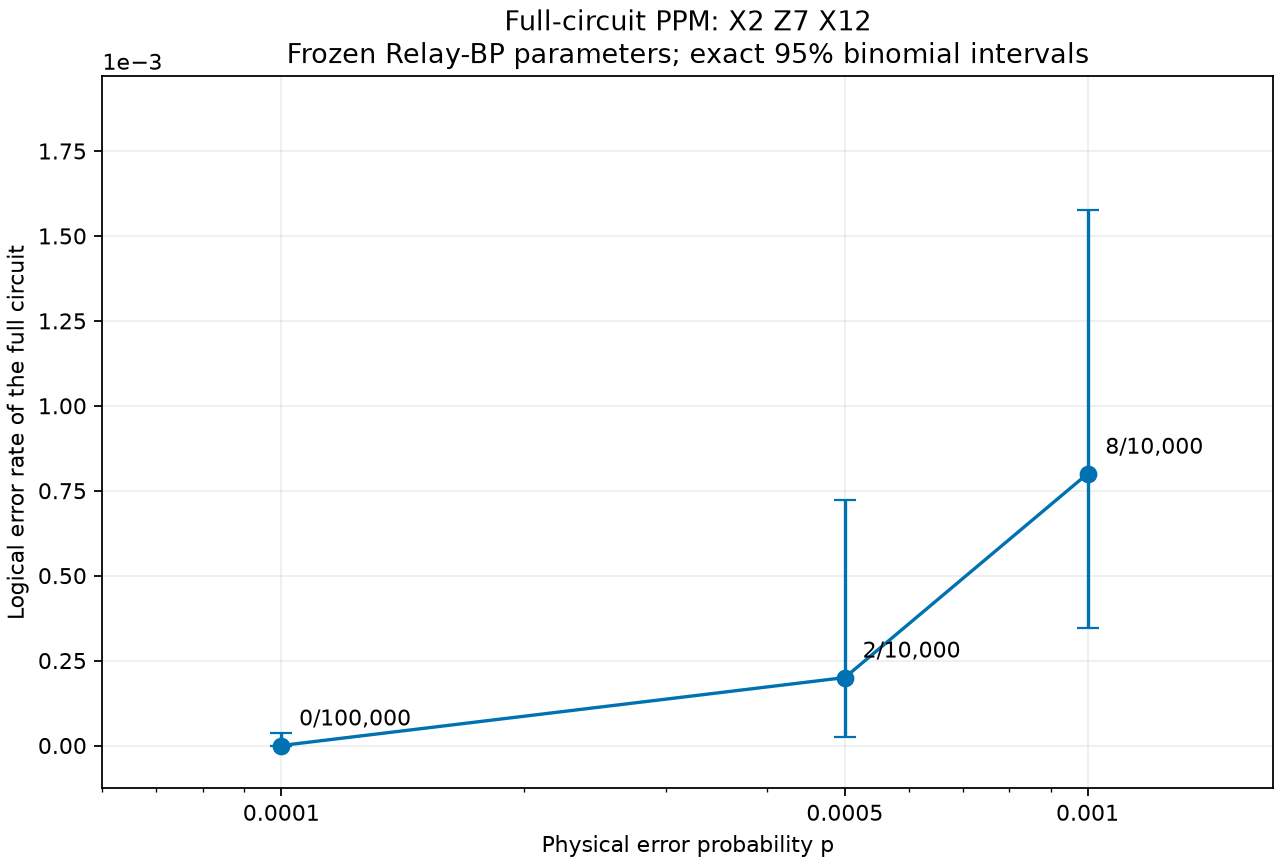

Zero observed failures are plotted at 0 with a nonzero confidence bound. They do not establish a zero true LER.


In [ ]:
# This entry attaches to the existing campaign; it does not repeat sampling.
helper_folder = ROOT / "notebooks" / "LogicalOps"
if str(helper_folder) not in sys.path:
    sys.path.insert(0, str(helper_folder))
from bb_ppm_large_sample import display_campaign

assert NOISE_MODEL == "circuit_level_with_idling"
assert ROUNDS == 10 and THREADS_PER_WORKER == 1
large_sample_view = display_campaign(
    LARGE_SAMPLE_RUN,
    midpoint_run=MIDPOINT_SAMPLE_RUN,
    expected_plan_sha256=plan_sha256,
    decoder_params=DECODER_PARAMS,
    shots_by_p=SHOTS_BY_P,
    workers=WORKER_PROCESSES,
    resume=RESUME_IF_STOPPED,
)
